# Mini-Project 4 — Rainfall Pattern & Crop Suitability Analyser

**Scenario.** An agricultural extension officer wants to compare rainfall regimes across regions and advise farmers on which months suit which crops.

**Data provenance.**

| Data | Source | Nature |
|---|---|---|
| Monthly rainfall, Kampala / Gulu / Mbarara (Sections 1–7) | Assignment PDF | **Illustrative (synthetic)** — not UNMA observations |
| Monthly rainfall 2015–2024 (Section 8, extension) | NASA POWER daily *PRECTOTCORR* (MERRA-2 corrected precipitation, mm/day), summed to months by `daily_to_monthly`; downloaded with `python -m src.rainfall` | **Real, satellite/reanalysis-derived** estimates at one grid point per town — not rain-gauge observations |
| Crop water needs | FAO (see References) | Seasonal needs, converted to monthly bands by a stated assumption |

All reusable logic is in `src/rainfall.py` (tested in `tests/test_rainfall.py`).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import math
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.spatial.distance import cosine as scipy_cosine_distance

from src.rainfall import (
    MONTHS, DAYS_PER_MONTH, Region, CropRule, cosine_similarity, pearson, euclidean,
    similarity_matrices, detect_seasons, load_power_csv,
)

POWER_CSV = PROJECT_ROOT / "data" / "nasa_power_monthly_rainfall.csv"
PROMINENCE_MM = 50.0
np.set_printoptions(precision=3, suppress=True, linewidth=120)

## 1. The `Region` class (Task 1)

In [2]:
ILLUSTRATIVE = "Illustrative (assignment PDF)"
regions = [
    Region("Kampala", [120, 140, 180, 200, 220, 180,  90,  70,  60, 100, 110, 130], ILLUSTRATIVE),
    Region("Gulu",    [  8,  25,  75, 160, 190, 145, 170, 215, 175, 150,  60,  15], ILLUSTRATIVE),
    Region("Mbarara", [ 70,  85, 120, 140,  90,  25,  20,  55, 100, 125, 120,  90], ILLUSTRATIVE),
]
print(f"{'Region':<9} {'Annual (mm)':>11} {'Mean (mm)':>10} {'Wettest':>12} {'Driest':>11} {'CV':>6}")
for r in regions:
    wm, wv = r.wettest_month(); dm, dv = r.driest_month()
    print(f"{r.name:<9} {r.annual_total():11.0f} {r.mean():10.1f} {wm:>6} {wv:4.0f} mm {dm:>5} {dv:4.0f} mm {r.cv():6.3f}")

Region    Annual (mm)  Mean (mm)      Wettest      Driest     CV
Kampala          1600      133.3    May  220 mm   Sep   60 mm  0.388
Gulu             1388      115.7    Aug  215 mm   Jan    8 mm  0.642
Mbarara          1040       86.7    Apr  140 mm   Jul   20 mm  0.444


Kampala is the wettest overall but the most *even* (lowest CV); Gulu has a long dry season (8 mm in January) and the highest CV, meaning rainfall is concentrated in fewer months.

## 2. `CropRule` and monthly classification (Task 2)

**Source.** FAO's water-harvesting manual, Chapter 2 (Table 2: seasonal crop water needs; Table 6: total growing period) gives: maize 500–800 mm over 125–180 days (grain), beans 300–500 mm over 95–110 days (dry beans), sorghum 450–650 mm over 120–130 days. FAO's maize crop-information page gives the same 500–800 mm for a medium-maturity grain crop.

**Stated conversion assumption.** The sources give mm per *season*; the task classifies *months*. Spreading the need evenly over the season, the least water per month is the low need over the longest season, and the most is the high need over the shortest season:

$$\text{low} = \frac{\text{need}_{\min}}{\text{days}_{\max}/30.44}, \qquad \text{high} = \frac{\text{need}_{\max}}{\text{days}_{\min}/30.44}.$$

Below the band is **Drought risk**; above it, **Excess rain (waterlogging risk)** — a warning, because rain above a crop's need only waterlogs poorly drained soil. Note that rainfall is not the same as water available to the crop: part evaporates or runs off.

In [3]:
FAO_SOURCE = "FAO water-harvesting manual, ch. 2, Tables 2 and 6 (fao.org/4/u3160e/u3160e04.htm)"
crops = [
    CropRule.from_seasonal("maize",   500, 800, 125, 180, FAO_SOURCE),
    CropRule.from_seasonal("beans",   300, 500,  95, 110, FAO_SOURCE),
    CropRule.from_seasonal("sorghum", 450, 650, 120, 130, FAO_SOURCE),
]
for c in crops:
    print(c)
print(f"\nHand check maize low: 500 / (180 / {DAYS_PER_MONTH:.2f}) = {500 / (180 / DAYS_PER_MONTH):.1f} mm")

CropRule('maize', good 84.5-194.8 mm/month)
CropRule('beans', good 83.0-160.2 mm/month)
CropRule('sorghum', good 105.4-164.9 mm/month)

Hand check maize low: 500 / (180 / 30.44) = 84.5 mm


In [4]:
symbol = {-1: "D", 0: "G", 1: "W"}
print("G = good, D = drought risk, W = excess rain (waterlogging risk)\n")
print(f"{'':<17}" + " ".join(f"{m:>3}" for m in MONTHS) + "   good months")
for c in crops:
    for r in regions:
        codes = c.codes_for_region(r)
        print(f"{c.crop + ' / ' + r.name:<17}" + " ".join(f"{symbol[x]:>3}" for x in codes) + f"   {int((codes == 0).sum()):>5}")
    print()

print("Full labels, Gulu, maize:")
for m, label in zip(MONTHS, crops[0].classify_region(regions[1])):
    print(f"  {m}: {label}")

G = good, D = drought risk, W = excess rain (waterlogging risk)

                 Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec   good months
maize / Kampala    G   G   G   W   W   G   G   D   D   G   G   G       8
maize / Gulu       D   D   D   G   G   G   G   W   G   G   D   D       6
maize / Mbarara    D   G   G   G   G   D   D   D   G   G   G   G       8

beans / Kampala    G   G   W   W   W   W   G   D   D   G   G   G       6
beans / Gulu       D   D   D   G   W   G   W   W   W   G   D   D       3
beans / Mbarara    D   G   G   G   G   D   D   D   G   G   G   G       8

sorghum / Kampala  G   G   W   W   W   W   D   D   D   D   G   G       4
sorghum / Gulu     D   D   D   G   W   G   W   W   W   G   D   D       3
sorghum / Mbarara  D   D   G   G   D   D   D   D   D   G   G   D       4

Full labels, Gulu, maize:
  Jan: Drought risk
  Feb: Drought risk
  Mar: Drought risk
  Apr: Good for maize
  May: Good for maize
  Jun: Good for maize
  Jul: Good for maize
  Aug: Excess rain (wa

## 3. Correcting last year's cosine method (Task 3)

`math.cos(x)` returns the cosine of an *angle* $x$ in radians — a single number in, a single number out. Applying it to rainfall values (e.g. `math.cos(120)`) produces meaningless numbers between −1 and 1 that depend on how many radians "120 mm" happens to be. Cosine **similarity** is the cosine of the angle *between two vectors*:

$$\cos\theta = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}.$$

`scipy.spatial.distance.cosine` returns the cosine **distance**, $1 - \cos\theta$, so we compare against $1 -$ that value.

In [5]:
k, m = regions[0].rainfall, regions[2].rainfall
print("Last year's mistake, math.cos on rainfall values:", [round(math.cos(v), 3) for v in k[:4]], "...  (meaningless)")
ours = cosine_similarity(k, m)
scipy_value = 1 - scipy_cosine_distance(k, m)
manual = float(np.dot(k, m) / (np.linalg.norm(k) * np.linalg.norm(m)))
print(f"Kampala vs Mbarara: ours = {ours:.6f}, 1 - scipy distance = {scipy_value:.6f}, by hand = {manual:.6f}")
print("Agree:", np.isclose(ours, scipy_value))

Last year's mistake, math.cos on rainfall values: [0.814, -0.198, -0.598, 0.487] ...  (meaningless)
Kampala vs Mbarara: ours = 0.891250, 1 - scipy distance = 0.891250, by hand = 0.891250
Agree: True


## 4. Similarity and distance matrices (Task 4)

In [6]:
mats = similarity_matrices(regions)
names = mats["names"]
for key, unit in (("cosine", "(unitless, 1 = same shape)"), ("pearson", "(unitless, -1 to 1)"), ("euclidean", "(mm)")):
    print(f"{key.capitalize()} {unit}")
    print(f"{'':<9}" + "".join(f"{n:>10}" for n in names))
    for i, n in enumerate(names):
        print(f"{n:<9}" + "".join(f"{v:10.3f}" for v in mats[key][i]))
    print()

Cosine (unitless, 1 = same shape)
            Kampala      Gulu   Mbarara
Kampala       1.000     0.787     0.891
Gulu          0.787     1.000     0.749
Mbarara       0.891     0.749     1.000

Pearson (unitless, -1 to 1)
            Kampala      Gulu   Mbarara
Kampala       1.000    -0.066     0.209
Gulu         -0.066     1.000    -0.174
Mbarara       0.209    -0.174     1.000

Euclidean (mm)
            Kampala      Gulu   Mbarara
Kampala       0.000   315.268   250.400
Gulu        315.268     0.000   312.800
Mbarara     250.400   312.800     0.000



In [7]:
# Why cosine can call a much wetter region "similar": scale does not change the angle.
wetter_mbarara = regions[2].rainfall * (regions[0].annual_total() / regions[2].annual_total())
print(f"Mbarara scaled to Kampala's annual total ({wetter_mbarara.sum():.0f} mm):")
print(f"  cosine with original Mbarara = {cosine_similarity(regions[2].rainfall, wetter_mbarara):.3f} (identical shape)")
print(f"  Euclidean distance           = {euclidean(regions[2].rainfall, wetter_mbarara):.1f} mm")

Mbarara scaled to Kampala's annual total (1600 mm):
  cosine with original Mbarara = 1.000 (identical shape)
  Euclidean distance           = 175.6 mm


**Interpretation.** Cosine similarity rates every pair as quite similar (0.75–0.89), yet Pearson correlation is near zero or negative for every pair. The difference is the mean: rainfall is never negative, so all three vectors point into the same "positive" region of 12-dimensional space and the angles between them are small whatever their seasonal timing. Pearson subtracts each region's mean first, so it measures whether wet and dry months *line up* — and they largely do not (Gulu's peak is in August, Kampala's in May).

Cosine is also blind to **scale**: Mbarara scaled up to Kampala's 1,600 mm has cosine similarity exactly 1 with the original, even though the two are about 176 mm apart in Euclidean distance. That is why cosine can call a much wetter region "similar": it compares the *shape* of the vector, never its size. For crop advice, absolute amounts matter, so Euclidean distance (in mm) and the crop bands are more relevant than cosine.

## 5. Detecting rainy seasons (Task 5)

`scipy.signal.find_peaks` marks a month as a peak if it is higher than both neighbours; the **prominence** is how far it stands above the surrounding valleys. Two choices determine the answer:

1. **The year is circular.** `find_peaks` never reports the first or last element, so a peak in December or January is invisible on a Jan–Dec array. We wrap the year (Oct–Dec placed before January, Jan–Mar after December).
2. **Threshold: prominence ≥ 50 mm.** Rationale: to count as a separate season, a peak should rise at least roughly a whole dry-season month's rainfall (≈50 mm) above the dip that separates it from the other season. **Transparency:** this value was fixed *after* inspecting the illustrative data's prominences, so it is not a blind choice; the sensitivity table below shows how the answer changes with the threshold.

**Known climate zones (for checking).** A CORDEX regional-model evaluation (Kisembe et al.) summarises Uganda as unimodal in the north and bimodal nearer the equator (major season March–May, shorter season September–November); FAO AQUASTAT likewise describes the Northern farming system as monomodal. **Expected: Kampala bimodal, Gulu unimodal, Mbarara bimodal.**

In [8]:
expected = {"Kampala": "bimodal", "Gulu": "unimodal", "Mbarara": "bimodal"}
k_linear = detect_seasons(regions[0], PROMINENCE_MM, circular=False)
k_circ = detect_seasons(regions[0], 0.0, circular=True)
print("Edge trap, Kampala, no threshold:")
print(f"  linear array : peaks {k_linear['months']}")
print(f"  circular year: peaks {k_circ['months']} with prominences {np.round(k_circ['prominences'], 0)} mm\n")

print(f"Threshold {PROMINENCE_MM:.0f} mm, circular year:")
for r in regions:
    s = detect_seasons(r, PROMINENCE_MM)
    ok = "matches" if s["regime"] == expected[r.name] else "DOES NOT match"
    print(f"  {r.name:<8} peaks {s['months']!s:<16} prominences {np.round(s['prominences'], 0)!s:<12} -> {s['regime']:<9} "
          f"({ok} known zone: {expected[r.name]})")

Edge trap, Kampala, no threshold:
  linear array : peaks ['May']
  circular year: peaks ['May', 'Dec'] with prominences [120.  10.] mm

Threshold 50 mm, circular year:
  Kampala  peaks ['May']          prominences [120.]       -> unimodal  (DOES NOT match known zone: bimodal)
  Gulu     peaks ['Aug']          prominences [207.]       -> unimodal  (matches known zone: unimodal)
  Mbarara  peaks ['Apr', 'Oct']   prominences [70. 55.]    -> bimodal   (matches known zone: bimodal)


In [9]:
print("Sensitivity of the regime to the prominence threshold (circular year):")
thresholds = [5, 25, 50, 75]
print(f"{'Region':<9}" + "".join(f"{t:>12} mm" for t in thresholds) + "   known zone")
for r in regions:
    print(f"{r.name:<9}" + "".join(f"{detect_seasons(r, t)['regime']:>15}" for t in thresholds) + f"   {expected[r.name]}")

Sensitivity of the regime to the prominence threshold (circular year):
Region              5 mm          25 mm          50 mm          75 mm   known zone
Kampala          bimodal       unimodal       unimodal       unimodal   bimodal
Gulu             bimodal        bimodal       unimodal       unimodal   unimodal
Mbarara          bimodal        bimodal        bimodal  no clear peak   bimodal


**Interpretation.** The circular wrap matters: on a plain Jan–Dec array Kampala's December rise is invisible. Even with it, **no threshold classifies all three illustrative regions correctly**: Kampala's December rise stands only about 10 mm above the January dip that separates it from the main season (prominence is measured from the higher of the two surrounding dips), so any threshold that rejects Gulu's small May peak (45 mm prominence) also rejects Kampala's second season. At 50 mm, Gulu and Mbarara match their known zones but Kampala is wrongly called unimodal.

This is a limitation of **twelve observations**: one year of monthly totals has very few points, a single unusual month can create or erase a peak, and month boundaries can split one season in two. Section 8 tests whether more data fixes this.

## 6. Visualisation (Task 6)

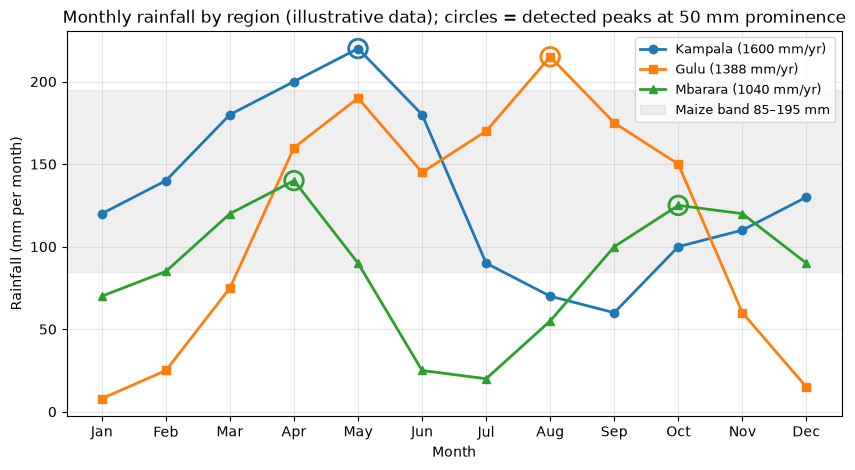

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
styles = {"Kampala": ("tab:blue", "o"), "Gulu": ("tab:orange", "s"), "Mbarara": ("tab:green", "^")}
for r in regions:
    color, marker = styles[r.name]
    ax.plot(MONTHS, r.rainfall, marker=marker, color=color, linewidth=2, label=f"{r.name} ({r.annual_total():.0f} mm/yr)")
    s = detect_seasons(r, PROMINENCE_MM)
    ax.scatter([MONTHS[i] for i in s["indices"]], r.rainfall[s["indices"]], s=180, facecolors="none", edgecolors=color, linewidths=2)
ax.axhspan(crops[0].low_mm, crops[0].high_mm, color="grey", alpha=0.12, label=f"Maize band {crops[0].low_mm:.0f}–{crops[0].high_mm:.0f} mm")
ax.set_xlabel("Month"); ax.set_ylabel("Rainfall (mm per month)")
ax.set_title("Monthly rainfall by region (illustrative data); circles = detected peaks at 50 mm prominence")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

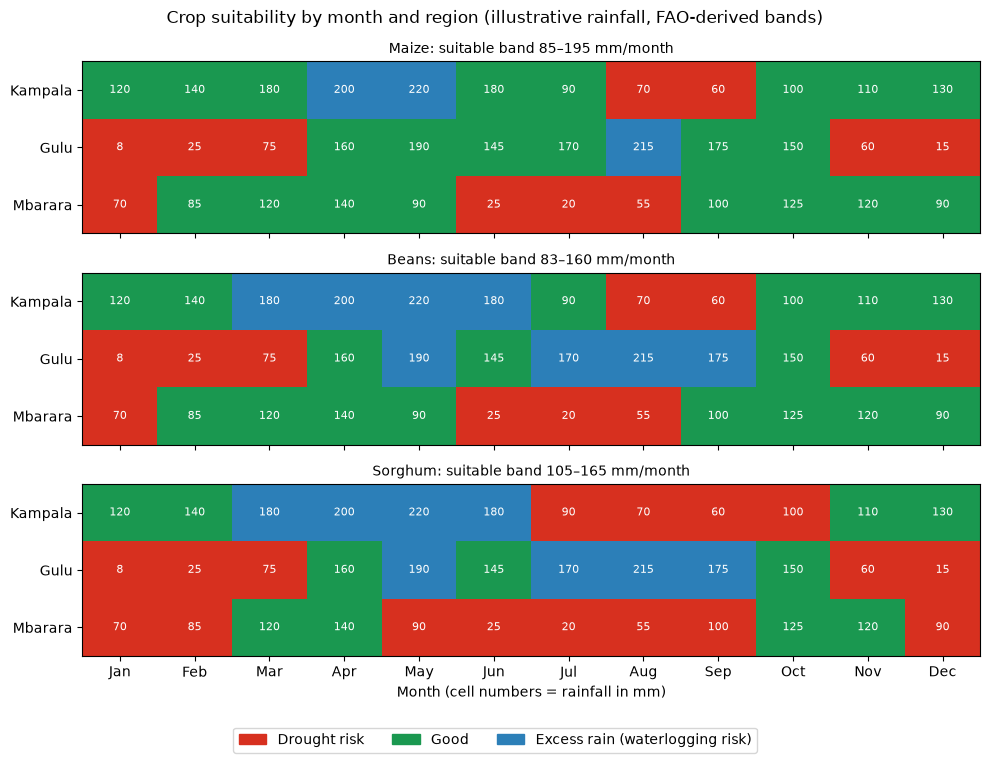

In [11]:
cmap = ListedColormap(["#d7301f", "#1a9850", "#2c7fb8"])          # drought, good, excess
norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)
fig, axes = plt.subplots(len(crops), 1, figsize=(10, 7.5), sharex=True)
for ax, c in zip(axes, crops):
    grid = np.array([c.codes_for_region(r) for r in regions])
    ax.imshow(grid, cmap=cmap, norm=norm, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(12):
            ax.text(j, i, f"{regions[i].rainfall[j]:.0f}", ha="center", va="center", fontsize=8, color="white")
    ax.set_yticks(range(len(regions)), [r.name for r in regions])
    ax.set_title(f"{c.crop.capitalize()}: suitable band {c.low_mm:.0f}–{c.high_mm:.0f} mm/month", fontsize=10)
axes[-1].set_xticks(range(12), MONTHS)
axes[-1].set_xlabel("Month (cell numbers = rainfall in mm)")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(3)]
fig.legend(handles, ["Drought risk", "Good", "Excess rain (waterlogging risk)"], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Crop suitability by month and region (illustrative rainfall, FAO-derived bands)")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Reading the heatmaps.** Maize has the widest band, so it has at least as many green cells as any other crop in every region (tied with beans in Mbarara). Beans and sorghum have narrower bands that Kampala and Gulu *overshoot* in their wettest months (blue), while Mbarara's moderate totals suit beans in eight months. Gulu's December–March block is red for every crop: without irrigation nothing grows in its dry season.

## 7. Advisory note for farmers in Gulu (Task 7)

In [12]:
ADVISORY = '''
Advisory note: planting in Gulu

This advice uses illustrative monthly rainfall and simple FAO-based rainfall ranges. Check the UNMA seasonal forecast before planting each year.

Gulu has one long rainy season, from about April to October, and a dry season from November to March. Rain from December to March is too little for maize, beans or sorghum without irrigation.

Maize is the best choice. Rainfall from April to October falls within the range maize needs in every month except August, which may be too wet on poorly drained land. Plant at the start of the rains, in late March or April, once the soil is moist. A medium-maturity variety will then flower in June or July, when rain is reliable; flowering is the stage at which maize suffers most from drought.

Beans are riskier: most months of the season are wetter than beans need. If you grow them, plant in April on well-drained soil or raised beds.

Sorghum tolerates drought but has fewer suitable months here; it is a reasonable choice on sandy soils.

Avoid planting after August: the crop would mature into the dry season.
'''.strip()

print(ADVISORY)
words = len(re.findall(r"\b[\w'-]+\b", ADVISORY))
print(f"\nWord count: {words} (limit 200) -> {'OK' if words <= 200 else 'TOO LONG'}")

Advisory note: planting in Gulu

This advice uses illustrative monthly rainfall and simple FAO-based rainfall ranges. Check the UNMA seasonal forecast before planting each year.

Gulu has one long rainy season, from about April to October, and a dry season from November to March. Rain from December to March is too little for maize, beans or sorghum without irrigation.

Maize is the best choice. Rainfall from April to October falls within the range maize needs in every month except August, which may be too wet on poorly drained land. Plant at the start of the rains, in late March or April, once the soil is moist. A medium-maturity variety will then flower in June or July, when rain is reliable; flowering is the stage at which maize suffers most from drought.

Beans are riskier: most months of the season are wetter than beans need. If you grow them, plant in April on well-drained soil or raised beds.

Sorghum tolerates drought but has fewer suitable months here; it is a reasonable choice

The note is based on the classification in Section 2 (maize "Good" in Gulu from April to October except August) and on FAO's ranking of maize as the most drought-sensitive of these crops, which is why it recommends timing flowering for the wettest reliable months. Section 8 checks the season timing against ten years of real data.

## 8. Extension: ten years of real rainfall (NASA POWER, 2015–2024)

Daily corrected precipitation was downloaded once for a point near each town (Kampala 0.35 °N 32.58 °E; Gulu 2.77 °N 32.30 °E; Mbarara 0.61 °S 30.65 °E) and summed to monthly totals. `daily_to_monthly` would have stopped on any missing value or incomplete month; none occurred. The file is committed, so this section runs offline.

In [13]:
power = load_power_csv(POWER_CSV)
real_regions = []
print(f"{'Region':<9} {'Years':>10} {'Mean annual (mm)':>17} {'Driest year':>12} {'Wettest year':>13}")
for r in regions:
    years, rain = power[r.name]
    totals = rain.sum(axis=1)
    real_regions.append(Region(f"{r.name} (NASA)", rain.mean(axis=0), "NASA POWER 2015-2024 monthly mean"))
    print(f"{r.name:<9} {years[0]}-{years[-1]} {totals.mean():17.0f} {totals.min():7.0f} ({years[totals.argmin()]}) "
          f"{totals.max():7.0f} ({years[totals.argmax()]})")

Region         Years  Mean annual (mm)  Driest year  Wettest year
Kampala   2015-2024              1490    1107 (2021)    1841 (2015)
Gulu      2015-2024              1442    1109 (2016)    2128 (2020)
Mbarara   2015-2024              1317     880 (2016)    1904 (2022)


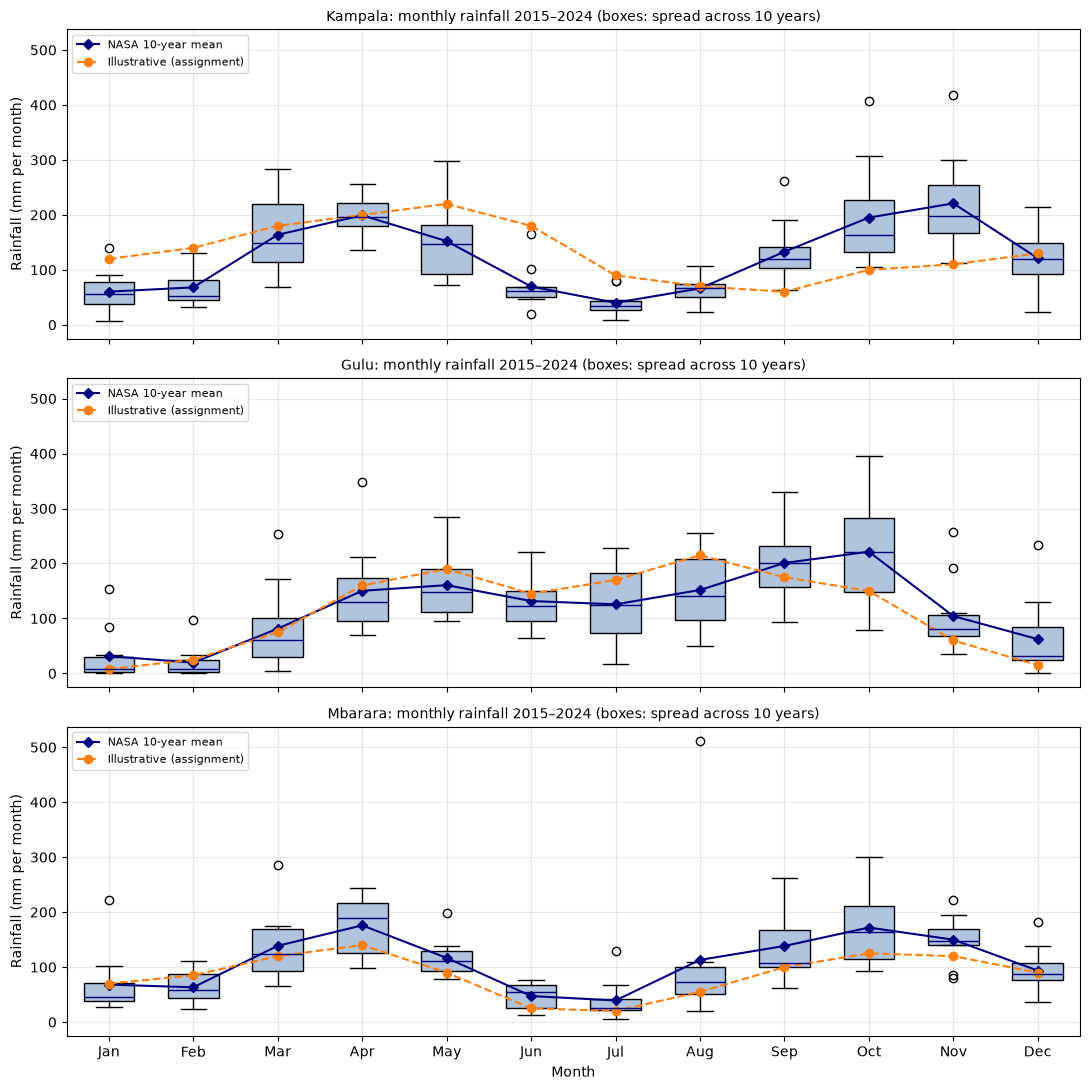

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True, sharey=True)
for ax, r, real in zip(axes, regions, real_regions):
    years, rain = power[r.name]
    ax.boxplot([rain[:, j] for j in range(12)], positions=range(1, 13), widths=0.6,
               patch_artist=True, boxprops=dict(facecolor="lightsteelblue"), medianprops=dict(color="navy"))
    ax.plot(range(1, 13), real.rainfall, "D-", color="navy", markersize=5, label="NASA 10-year mean")
    ax.plot(range(1, 13), r.rainfall, "o--", color="tab:orange", label="Illustrative (assignment)")
    ax.set_title(f"{r.name}: monthly rainfall 2015–2024 (boxes: spread across 10 years)", fontsize=10)
    ax.set_ylabel("Rainfall (mm per month)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper left")
axes[-1].set_xticks(range(1, 13), MONTHS)
axes[-1].set_xlabel("Month")
fig.tight_layout()
plt.show()

In [15]:
print(f"Season detection at {PROMINENCE_MM:.0f} mm on the 10-year mean:")
for r, real in zip(regions, real_regions):
    s = detect_seasons(real, PROMINENCE_MM)
    ok = "matches" if s["regime"] == expected[r.name] else "DOES NOT match"
    print(f"  {real.name:<16} peaks {s['months']!s:<16} prominences {np.round(s['prominences'], 0)!s:<12} -> {s['regime']:<9} ({ok})")

print(f"\nRobustness: same rule on the 10-year MEDIAN of each month (less sensitive to one extreme year):")
for r in regions:
    s = detect_seasons(Region(r.name, np.median(power[r.name][1], axis=0), "NASA median"), PROMINENCE_MM)
    print(f"  {r.name:<8} peaks {s['months']!s:<16} -> {s['regime']}")

years_m, rain_m = power["Mbarara"]
aug = rain_m[:, 7]
print(f"\nMbarara August by year (mm): {dict(zip(years_m.tolist(), np.round(aug).astype(int).tolist()))}")
print(f"  mean {aug.mean():.0f} mm, median {np.median(aug):.0f} mm, mean without the largest year {np.sort(aug)[:-1].mean():.0f} mm")
print(f"\nSame rule applied to each single year (12 values each):")
for r in regions:
    years, rain = power[r.name]
    regimes = [detect_seasons(Region("y", row, "NASA"), PROMINENCE_MM)["regime"] for row in rain]
    counts = {k: regimes.count(k) for k in ("unimodal", "bimodal", "multimodal", "no clear peak") if regimes.count(k)}
    print(f"  {r.name:<8} {counts}  (known zone: {expected[r.name]})")

print("\nYear-to-year variability: coefficient of variation of each month across the 10 years")
print(f"{'':<9}" + " ".join(f"{m:>5}" for m in MONTHS))
for r in regions:
    rain = power[r.name][1]
    print(f"{r.name:<9}" + " ".join(f"{v:5.2f}" for v in rain.std(axis=0, ddof=1) / rain.mean(axis=0)))

Season detection at 50 mm on the 10-year mean:
  Kampala (NASA)   peaks ['Apr', 'Nov']   prominences [139. 161.]  -> bimodal   (matches)
  Gulu (NASA)      peaks ['Oct']          prominences [202.]       -> unimodal  (matches)
  Mbarara (NASA)   peaks ['Apr', 'Oct']   prominences [113. 109.]  -> bimodal   (matches)

Robustness: same rule on the 10-year MEDIAN of each month (less sensitive to one extreme year):
  Kampala  peaks ['Apr', 'Nov']   -> bimodal
  Gulu     peaks ['Oct']          -> unimodal
  Mbarara  peaks ['Apr', 'Oct']   -> bimodal

Mbarara August by year (mm): {2015: 49, 2016: 44, 2017: 59, 2018: 84, 2019: 106, 2020: 67, 2021: 109, 2022: 512, 2023: 20, 2024: 80}
  mean 113 mm, median 74 mm, mean without the largest year 69 mm

Same rule applied to each single year (12 values each):
  Kampala  {'bimodal': 8, 'multimodal': 2}  (known zone: bimodal)
  Gulu     {'unimodal': 1, 'bimodal': 6, 'multimodal': 3}  (known zone: unimodal)
  Mbarara  {'bimodal': 9, 'multimodal': 1}  (k

**Interpretation.**

* **More data fixes the season detection.** On the ten-year means, the same 50 mm rule classifies **Kampala bimodal, Gulu unimodal and Mbarara bimodal — all three match the known climate zones**, whereas the illustrative data managed only two. The illustrative Kampala series simply has an unrealistically weak second season.
* **The result is robust.** Using each month's ten-year *median* instead of the mean gives the same three regimes.
* **One suspicious value.** Mbarara's August 2022 total (≈512 mm) is several times every other August in the record and lifts the August mean from about 69 to about 113 mm. We keep it — there is no evidence it is wrong — but a value like this should be checked against UNMA station records before it is used for advice, and it shows why medians and box plots are safer summaries than means for rainfall.
* **Single years are unreliable.** Applied to individual years, the same rule often finds extra peaks — Gulu looks bimodal in most single years because its long season usually has a mid-season dip. The regime is a property of the *climate* (many years), not of any one year, which is exactly why twelve monthly observations are a weak basis for classification.
* **Variability is large.** The boxes are wide, and in the dry-season months the year-to-year coefficient of variation exceeds 1 in Gulu — rainfall there in December–February ranges from almost none to occasional wet months. Farmers' risk comes from this spread, not from the average.
* **The illustrative series are not realistic in detail.** NASA puts Gulu's main peak in September–October rather than August, and shows a clear second season in Kampala. The Gulu advisory's core message (one long season, plant at onset in March–April, avoid the November–March dry season) is consistent with the real data; its detail about August being "too wet" is not, and should be treated as an artefact of the illustrative data.
* Kampala's wettest November in the record (2015, 417 mm) coincides with a strong El Niño, and the second wettest (2023, 300 mm) with another El Niño year — consistent with Phillips & McIntyre's finding that November rainfall at bimodal sites in Uganda is enhanced in El Niño years — an observation, not a test, with only ten years.

**Limitations of the extension.** NASA POWER values are model/satellite estimates for a grid cell of roughly half a degree, not rain-gauge measurements at the towns; they smooth local extremes, so station data from UNMA would be the next check. Ten years is short for climate statistics (the WMO convention is 30-year normals).

## 9. Findings & Limitations

*Word count: approximately 265.*

**Findings.** The three illustrative regions differ more in timing than cosine similarity suggests: cosine rates every pair as similar (0.75–0.89), but Pearson correlation is near zero or negative, because cosine ignores both the mean and the scale of rainfall and so cannot separate a May-peaking regime from an August-peaking one. For crop advice, the absolute amounts in the FAO-derived bands matter most: maize, with the widest band, suits at least as many months as either other crop in every region, while beans and sorghum are often over-watered in Kampala's and Gulu's wettest months. Gulu's dry season rules out all three crops from December to March. Peak detection on twelve illustrative values could not reproduce all three known climate zones at any threshold, but on ten years of NASA POWER data the same 50 mm rule classified Kampala and Mbarara as bimodal and Gulu as unimodal, exactly as expected.

**Limitations.** The suitability bands assume a crop's seasonal water need is spread evenly over its season, ignore evapotranspiration, soil storage and drainage, and treat rainfall as if it were all available to the crop; "excess rain" is a warning, not a measured waterlogging risk. The illustrative data are synthetic, and the advisory note inherits their quirks — the real data put Gulu's peak in September–October, not August. The 50 mm prominence threshold was fixed after seeing the data, and single years remain noisy. NASA POWER values are gridded estimates rather than gauge observations, and ten years is a short climate record. Farmers should combine this kind of analysis with UNMA seasonal forecasts and local experience.

## References

* FAO. *Water harvesting* manual, Chapter 2 "Water and soil requirements", Tables 2 (seasonal crop water needs), 6 (total growing period) and 7 (drought sensitivity). https://www.fao.org/4/u3160e/u3160e04.htm
* FAO. Land & Water — Crop information: Maize. https://www.fao.org/land-water/databases-and-software/crop-information/maize
* Kisembe, J. et al. Evaluation of rainfall simulations over Uganda in CORDEX regional climate models. *Theoretical and Applied Climatology*. https://doi.org/10.1007/s00704-018-2643-x
* FAO AQUASTAT. Country profile — Uganda. https://openknowledge.fao.org/server/api/core/bitstreams/73d0f6bd-80ae-4217-8eb0-a89dc49ef49d/content
* Phillips, J. and McIntyre, B. (2000). ENSO and interannual rainfall variability in Uganda: implications for agricultural management. Abstract: https://www.giss.nasa.gov/pubs/abs/ph09000j.html
* NASA Langley Research Center, POWER Project: daily *PRECTOTCORR*, AG community, accessed via https://power.larc.nasa.gov/api/temporal/daily/point